# NASA Kepler Objects of Interest

## Exoplanet Candidate Classification

The Kepler Space Observatory is a NASA-build satellite that was launched in 2009. The telescope is dedicated to searching for exoplanets in star systems besides our own, with the ultimate goal of possibly finding other habitable planets besides our own. The original mission ended in 2013 due to mechanical failures, but the telescope has nevertheless been functional since 2014 on a "K2" extended mission.

Kepler had verified 1284 new exoplanets as of May 2016. As of October 2017 there are over 3000 confirmed exoplanets total (using all detection methods, including ground-based ones). The telescope is still active and continues to collect new data on its extended mission.

This dataset is a cumulative record of all observed Kepler "objects of interest" basically, all of the approximately 10,000 exoplanet candidates Kepler has taken observations on.

It contains information about thousands of objects observed by the Kepler Space
Telescope while searching for planets outside our solar system. Each object is described using
measurements related to the possible planet, its orbit, the observed transit signal, and the star that it
may be orbiting.

This dataset was published as-is by NASA. You can access the original table here[https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=koi]. More data from the Kepler mission is available from the same source here[https://exoplanetarchive.ipac.caltech.edu/docs/data.html].

Our task is to build a machine-learning model that can distinguish between potential exoplanets and
false positive detections. The aim is to investigate whether machine learning can help scientists identify
the most promising observations for further study.

An important part of this project is deciding which variables should be used by the model. Some fields in
the dataset may contain information that was produced after scientists had already investigated or
classified an object. Using these variables could make the model appear much more accurate than it
really is.

In addition to reporting model performance, we will investigate where the model makes mistakes,
such as weak signals, unusual stars, missing measurements, or false positives that closely resemble real
planets.

# A. Setup

### A.1 Imports and Data

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/cumulative.csv')
df.shape

(9564, 50)

# B. Data Assessment

### B.1 Initial Inspection

In [7]:
df.head()

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [8]:
df.dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              9564 non-null   int64  
 1   kepid              9564 non-null   int64  
 2   kepoi_name         9564 non-null   str    
 3   kepler_name        2294 non-null   str    
 4   koi_disposition    9564 non-null   str    
 5   koi_pdisposition   9564 non-null   str    
 6   koi_score          8054 non-null   float64
 7   koi_fpflag_nt      9564 non-null   int64  
 8   koi_fpflag_ss      9564 non-null   int64  
 9   koi_fpflag_co      9564 non-null   int64  
 10  koi_fpflag_ec      9564 non-null   int64  
 11  koi_period         9564 non-null   float64
 12  koi_period_err1    9110 non-null   float64
 13  koi_period_err2    9110 non-null   float64
 14  koi_time0bk        9564 non-null   float64
 15  koi_time0bk_err1   9110 non-null   float64
 16  koi_time0bk_err2   9110 non-null   

##### Notes: 
Here we can see 9564 rows, 50 columns initially which is large enough for reliable ML.

koi_score has 8054 non-null and is a float, looks like a useful feature but it’s probably post-review leakage.

koi_teq_err1 and koi_teq_err2 are 0 non-null so we drop them since theyre completely empty.

### B.2 Drop Leakage and Irrelevant Columns

In [9]:
#leakage is whats produced after human review
#irrelevant data is stuff like IDs, names and coordinates

drop_cols = [
    'rowid', 'kepid', 'kepoi_name', 'kepler_name',  # identifiers
    'koi_pdisposition',                               # leakage: preliminary human call
    'koi_score',                                      # leakage: post-review confidence
    'koi_fpflag_nt', 'koi_fpflag_ss',               # leakage: false positive flags set by reviewers
    'koi_fpflag_co', 'koi_fpflag_ec',
    'koi_tce_delivname',                              # pipeline delivery label
    'koi_teq_err1', 'koi_teq_err2',                  # 0 non-null, useless
]

df = df.drop(columns=drop_cols)
df.shape

(9564, 37)

##### Notes:
koi_disposition has 3 classes (CONFIRMED, CANDIDATE, FALSE POSITIVE), we’ll need to decide how to handle CONFIRMED in B.3

### B.3 Define Target Variable:

In [10]:
#keep only CANDIDATE and FALSE POSITIVE (we drop CONFIRMED, it's a post-review label)
df = df[df['koi_disposition'].isin(['CANDIDATE', 'FALSE POSITIVE'])]

df['target'] = (df['koi_disposition'] == 'CANDIDATE').astype(int)
df = df.drop(columns=['koi_disposition'])

df['target'].value_counts()

target
0    5023
1    2248
Name: count, dtype: int64

##### Notes:
kepler_name is only 2294 non-null, most objects aren’t confirmed named planets which is expected

### B.4 Data Missingness Analysis

In [11]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
print(f"\nmissing as % of rows:")
print((missing / len(df) * 100).round(2))

koi_steff_err2       469
koi_srad_err2        467
koi_slogg_err1       467
koi_slogg_err2       467
koi_srad_err1        467
koi_steff_err1       467
koi_period_err1      453
koi_depth_err1       453
koi_duration_err2    453
koi_period_err2      453
koi_time0bk_err1     453
koi_time0bk_err2     453
koi_impact_err1      453
koi_impact_err2      453
koi_duration_err1    453
koi_depth_err2       453
koi_prad_err2        362
koi_prad             362
koi_depth            362
koi_impact           362
koi_prad_err1        362
koi_model_snr        362
koi_teq              362
koi_steff            362
koi_slogg            362
koi_srad             362
koi_tce_plnt_num     338
koi_insol_err1       320
koi_insol            320
koi_insol_err2       320
koi_kepmag             1
dtype: int64

missing as % of rows:
koi_steff_err2       6.45
koi_srad_err2        6.42
koi_slogg_err1       6.42
koi_slogg_err2       6.42
koi_srad_err1        6.42
koi_steff_err1       6.42
koi_period_err1      6.23
koi_dep

##### Notes:

All missing values are under 7%, low enough to fill in without dropping rows or columns. The missingness falls into error columns like koi_steff_err2 and koi_srad_err1 at around 6%, and core feature columns like koi_prad, koi_depth, and koi_model_snr at around 5%. The error columns will be dropped in preprocessing. The core features will be median imputed.

The missingness in core features is not random. Objects missing koi_model_snr or koi_prad are probably poorly observed or low-quality detections, this could come up during error analysis.

# C. Exploratory Data Analysis

### C.1 Class Distribution:

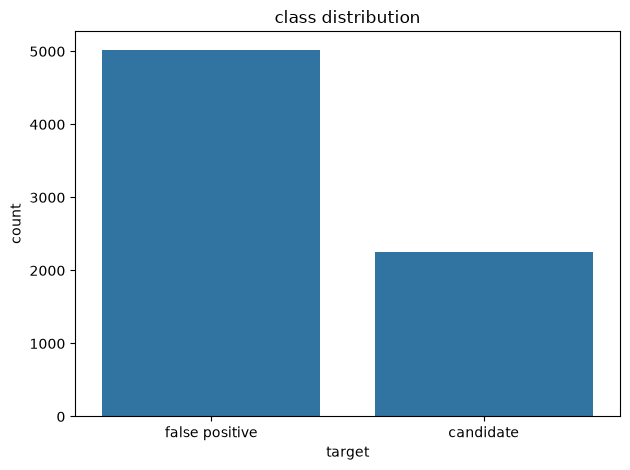

class ratio: 2.23:1 (false positive:candidate)


In [12]:
sns.countplot(x='target', data=df)
plt.xticks([0, 1], ['false positive', 'candidate'])
plt.title('class distribution')
plt.tight_layout()
plt.show()

print(f"class ratio: {5023/2248:.2f}:1 (false positive:candidate)")

##### Notes:

The dataset is imbalanced, with about 2.23 false positives for every candidate. This means a model that predicts false positive for everything would get around 69% accuracy, so accuracy alone is not a reliable metric here. We use class_weight='balanced' in all models to account for this, and rely on F1 and ROC-AUC as the primary evaluation metrics.

### C.2 Feature Distributions:

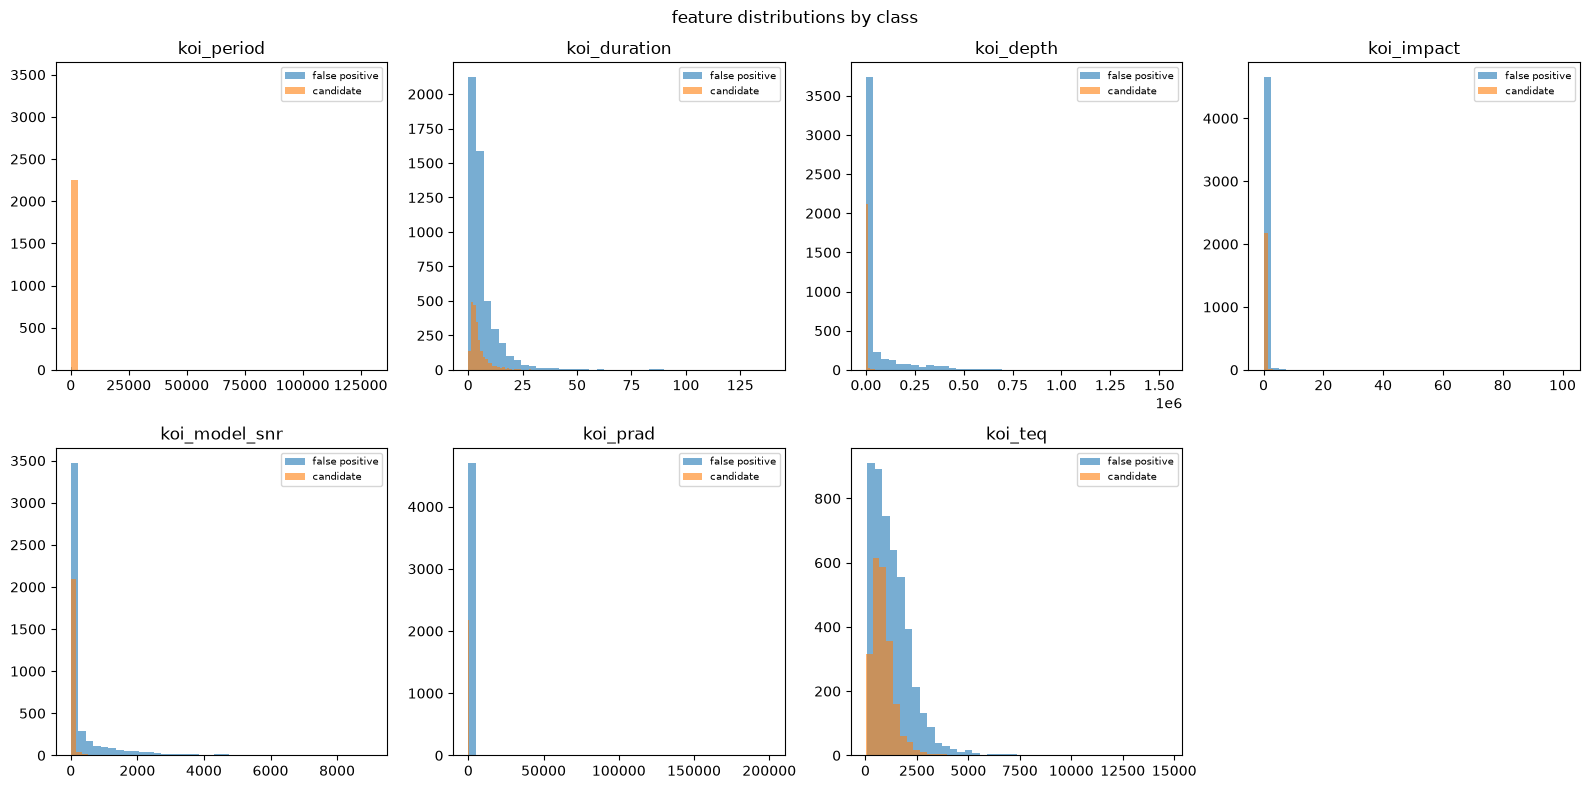

In [41]:
core_features = ['koi_period', 'koi_duration', 'koi_depth', 'koi_impact',
                 'koi_model_snr', 'koi_prad', 'koi_teq']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(core_features):
    axes[i].hist(df[df['target']==0][feature].dropna(), bins=40, alpha=0.6, label='false positive')
    axes[i].hist(df[df['target']==1][feature].dropna(), bins=40, alpha=0.6, label='candidate')
    axes[i].set_title(feature)
    axes[i].legend(fontsize=7)

# hide the empty 8th subplot
axes[-1].set_visible(False)

plt.suptitle('feature distributions by class')
plt.tight_layout()
plt.show()

##### Notes:

Most features are heavily right skewed with activity mostly at low values. False positives are more prominent across almost all features, consistent with the class imbalance seen in C.1. koi_period shows only candidate-exclusive spike. koi_teq shows the most overall activity with both classes present, though false positives still more than candidates. Features like koi_impact, koi_model_snr, and koi_prad are almost entirely false positive with few candidates visible, which shows how rare strong clean signals are in the dataset.

### C.3 Correlation Heatmap

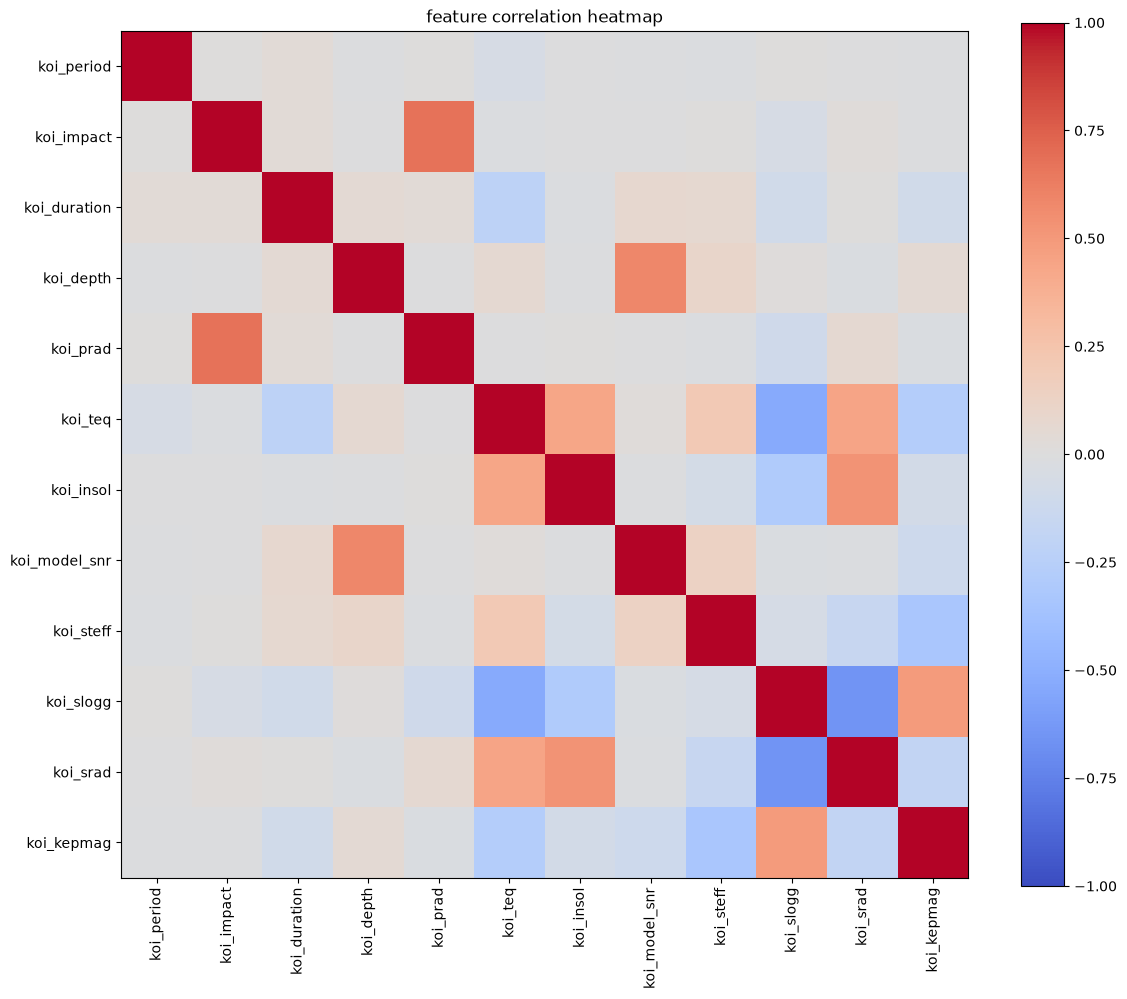

In [44]:
import matplotlib.pyplot as plt
import numpy as np

numeric_df = df.select_dtypes(include=np.number).drop(columns=['target'])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

ax.set_title('feature correlation heatmap')
plt.tight_layout()
plt.show()

##### Notes:

Most features are largely independent of each other, with strong correlation only along the diagonal as expected. The bottom right quadrant shows some moderate positive and negative correlations among the stellar property features like koi_steff, koi_slogg, koi_srad, and koi_kepmag. This makes sense as these properties describe the same star and are related.

# D. Data Preprocessing

### D.1 Drop Irrelevant Columns:

In [ ]:
#drop error columns and low-value features
err_cols = [c for c in df.columns if '_err' in c]
extra_drop = ['koi_time0bk', 'koi_tce_plnt_num', 'ra', 'dec']

df = df.drop(columns=err_cols + extra_drop)
print(df.shape)
print(df.columns.tolist())

(7271, 13)
['koi_period', 'koi_impact', 'koi_duration', 'koi_depth', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_model_snr', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag', 'target']


### D.2 Handling Missing Values:

In [ ]:
from sklearn.impute import SimpleImputer

#separate features and target before any fitting
X = df.drop(columns=['target'])
y = df['target']

#fit imputer on full X for now (we'll redo this properly inside the pipeline later)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

print(X_imputed.isnull().sum().sum())  #should be 0

0


### D.3 Train/Test Split:

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(), y_test.value_counts())

(5816, 12) (1455, 12)
target
0    4018
1    1798
Name: count, dtype: int64 target
0    1005
1     450
Name: count, dtype: int64


##### Notes:

error columns were dropped first since they add noise without value and have missingness. Identifier and coordinate columns like ra, dec, and koi_tce_plnt_num were also removed as they carry no meaning for classification. This left 12 core features.

Missing values in the remaining features were filled using median imputation. Median was chosen over mean because several features are heavily right skewed, like we saw in C.2, making the median better.

The data was then split 80/20 into train and test sets with stratification to preserve the class ratio. The test set is held out and only opened once during final evaluation in section F, all model selection and tuning happens on the training set only.

# E. Modeling

### E.1 Baseline, Logistic Regression

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

lr_cv = cross_validate(lr_pipeline, X_train, y_train, cv=cv,
                        scoring=['accuracy', 'f1', 'roc_auc'],
                        return_train_score=True)

print("logistic regression cv results:")
for metric in ['accuracy', 'f1', 'roc_auc']:
    train_score = lr_cv[f'train_{metric}'].mean()
    val_score = lr_cv[f'test_{metric}'].mean()
    print(f"  {metric}: train={train_score:.4f}, val={val_score:.4f}")

logistic regression cv results:
  accuracy: train=0.6747, val=0.6756
  f1: train=0.6211, val=0.6211
  roc_auc: train=0.7649, val=0.7608


##### Notes:

this is the simplest model in the comparison, it makes no assumptions about feature interactions.

Train and validation scores are almost identical across all metrics, meaning the model is not overfitting, it simply lacks the capacity to capture nonlinear or complex relationships in the data. ROC-AUC gives 0.76, and F1 gives 0.62 which reflects the difficulty of the class imbalance even with class_weight='balanced' applied.

### E.2 Random Forest

#### E.2.1 Default

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_cv = cross_validate(rf_pipeline, X_train, y_train, cv=cv,
                       scoring=['accuracy', 'f1', 'roc_auc'],
                       return_train_score=True)

print("random forest cv results:")
for metric in ['accuracy', 'f1', 'roc_auc']:
    train_score = rf_cv[f'train_{metric}'].mean()
    val_score = rf_cv[f'test_{metric}'].mean()
    print(f"  {metric}: train={train_score:.4f}, val={val_score:.4f}")

random forest cv results:
  accuracy: train=0.9991, val=0.7987
  f1: train=0.9985, val=0.6858
  roc_auc: train=1.0000, val=0.8559


#### E.2.2 Tuned / GridSearch

In [20]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__max_depth': [5, 10, 20, None],
    'model__min_samples_leaf': [1, 5, 10],
    'model__n_estimators': [100, 200]
}

rf_grid = GridSearchCV(
    rf_pipeline, param_grid, cv=cv,
    scoring='roc_auc', n_jobs=-1, return_train_score=True
)

rf_grid.fit(X_train, y_train)

print(f"best params: {rf_grid.best_params_}")
print(f"best val roc_auc: {rf_grid.best_score_:.4f}")

best params: {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
best val roc_auc: 0.8614


#### E.2.3 Tuned CV Results

In [23]:
rf_tuned_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        max_depth=None,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

#rerun cv on tuned rf to get full metric picture
rf_tuned_cv = cross_validate(rf_tuned_pipeline, X_train, y_train, cv=cv,
                              scoring=['accuracy', 'f1', 'roc_auc'],
                              return_train_score=True)

print("random forest (tuned) cv results:")
for metric in ['accuracy', 'f1', 'roc_auc']:
    train_score = rf_tuned_cv[f'train_{metric}'].mean()
    val_score = rf_tuned_cv[f'test_{metric}'].mean()
    print(f"  {metric}: train={train_score:.4f}, val={val_score:.4f}")

random forest (tuned) cv results:
  accuracy: train=0.9136, val=0.7930
  f1: train=0.8710, val=0.6909
  roc_auc: train=0.9813, val=0.8614


##### Notes:

Random forest is the second model and the strongest classical approach in this comparison. it can capture nonlinear relationships and feature interactions without any actual feature engineering.

The default model showed alot of overfitting, with train ROC-AUC 1.0 dropping to 0.856 on validation. This is typical for random forests with unconstrained tree depth. GridSearchCV was used to tune max_depth, min_samples_leaf, and n_estimators, with ROC-AUC as the scoring metric.

The best configuration used min_samples_leaf=5 and max_depth=None with 200 estimators. Keeping max_depth=None but having a minimum leaf size reduced overfitting here, each tree still grows deep but needs at least 5 samples to make a split decision. The overfit gap dropped from 1.0 to 0.981 on train with validation ROC-AUC improving slightly to 0.861, a good improvement over logistic regression which was 0.761.

### E.3 MLP Classifier

#### E.3.1 Default

In [24]:
from sklearn.neural_network import MLPClassifier

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        max_iter=500,
        random_state=42
    ))
])

mlp_cv = cross_validate(mlp_pipeline, X_train, y_train, cv=cv,
                         scoring=['accuracy', 'f1', 'roc_auc'],
                         return_train_score=True)

print("mlp cv results:")
for metric in ['accuracy', 'f1', 'roc_auc']:
    train_score = mlp_cv[f'train_{metric}'].mean()
    val_score = mlp_cv[f'test_{metric}'].mean()
    print(f"  {metric}: train={train_score:.4f}, val={val_score:.4f}")

mlp cv results:
  accuracy: train=0.8278, val=0.7787
  f1: train=0.6961, val=0.6103
  roc_auc: train=0.9001, val=0.8337


#### E.3.2 Tuned / GridSearch

In [25]:
mlp_param_grid = {
    'model__hidden_layer_sizes': [(64,), (64, 32), (128, 64)],
    'model__alpha': [0.0001, 0.001, 0.01],  #l2 regularization
    'model__learning_rate_init': [0.001, 0.01]
}

mlp_grid = GridSearchCV(
    mlp_pipeline, mlp_param_grid, cv=cv,
    scoring='roc_auc', n_jobs=-1, return_train_score=True
)

mlp_grid.fit(X_train, y_train)

print(f"best params: {mlp_grid.best_params_}")
print(f"best val roc_auc: {mlp_grid.best_score_:.4f}")

best params: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64, 32), 'model__learning_rate_init': 0.001}
best val roc_auc: 0.8355


#### E.3.3 Tuned CV Results

In [26]:
mlp_tuned_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPClassifier(
        hidden_layer_sizes=(64, 32),
        alpha=0.01,
        learning_rate_init=0.001,
        activation='relu',
        max_iter=500,
        random_state=42
    ))
])

# rerun cv on tuned mlp to get full metric picture
mlp_tuned_cv = cross_validate(mlp_tuned_pipeline, X_train, y_train, cv=cv,
                               scoring=['accuracy', 'f1', 'roc_auc'],
                               return_train_score=True)

print("mlp (tuned) cv results:")
for metric in ['accuracy', 'f1', 'roc_auc']:
    train_score = mlp_tuned_cv[f'train_{metric}'].mean()
    val_score = mlp_tuned_cv[f'test_{metric}'].mean()
    print(f"  {metric}: train={train_score:.4f}, val={val_score:.4f}")

mlp (tuned) cv results:
  accuracy: train=0.8251, val=0.7828
  f1: train=0.7021, val=0.6310
  roc_auc: train=0.8959, val=0.8355


##### Notes:

the MLP classifier adds nonlinearity through hidden layers and learned feature interactions, representing more than logistic regression and being more structured than a random forest.

The default configuration used two hidden layers of size 64 and 32 with relu activation. It had a validation ROC-AUC of 0.834, between logistic regression and random forest. Overfitting was moderate with a train/val gap of around 0.06, better than random forest.

GridSearchCV tuned the hidden layer sizes, l2 regularization strength via alpha, and learning rate. The best configuration kept the same layer sizes with alpha=0.01, this means regularization was needed. Tuning produced almost no improvement 0.834 -> 0.836, so the MLP is close to its max performance with this feature set and sample size.

The MLP does not do better than the tuned random forest, but it overfits less. This is a tradeoff that comes with more complexity, to be discussed in the conclusion.

# F. Evaluation

### F.1 Fit and Test Set Evaluation

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

#fit all three on full training set
lr_pipeline.fit(X_train, y_train)
rf_tuned_pipeline.fit(X_train, y_train)
mlp_tuned_pipeline.fit(X_train, y_train)

#predict
models = {
    'logistic regression': lr_pipeline,
    'random forest (tuned)': rf_tuned_pipeline,
    'mlp (tuned)': mlp_tuned_pipeline
}

print("test set results:")
print(f"{'model':<25} {'accuracy':>10} {'f1':>10} {'roc_auc':>10}")
print("-" * 58)

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    print(f"{name:<25} {acc:>10.4f} {f1:>10.4f} {auc:>10.4f}")

test set results:
model                       accuracy         f1    roc_auc
----------------------------------------------------------
logistic regression           0.6825     0.6225     0.7762
random forest (tuned)         0.8027     0.6995     0.8795
mlp (tuned)                   0.7924     0.6505     0.8506


#### Notes:

Results are similar with cross-validation for the three models, meaning the CV estimates are reliable. 

Random forest leads on all metrics with a ROC-AUC of 0.88,then MLP at 0.85 and then logistic regression at 0.78. The gap between logistic regression and the other two shows that nonlinearity is important here. F1 scores are lower relative to ROC-AUC, this shows that its hard to make clean decisions under class imbalance.

### F.2 Confusion Matrices

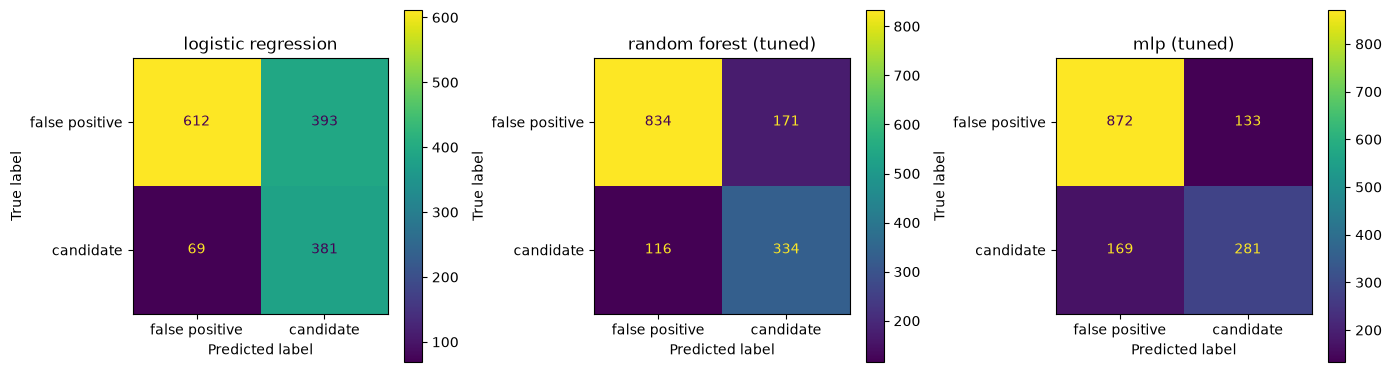

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['false positive', 'candidate'])
    disp.plot(ax=ax, colorbar=True)
    ax.set_title(name)

plt.tight_layout()
plt.show()

#### Notes:

Random forest gets the most correct candidates with 334 true positives, compared to 281 for MLP and 381 for LR. LR does have higher correct candidate count but at a big cost of way more false alarms, 393 false positives vs 171 for RF. MLP flags the fewest false positives but also catches the fewest candidates. Overall RF has the best balance between catching real candidates and avoiding false alarms.

### F.3 ROC Curves

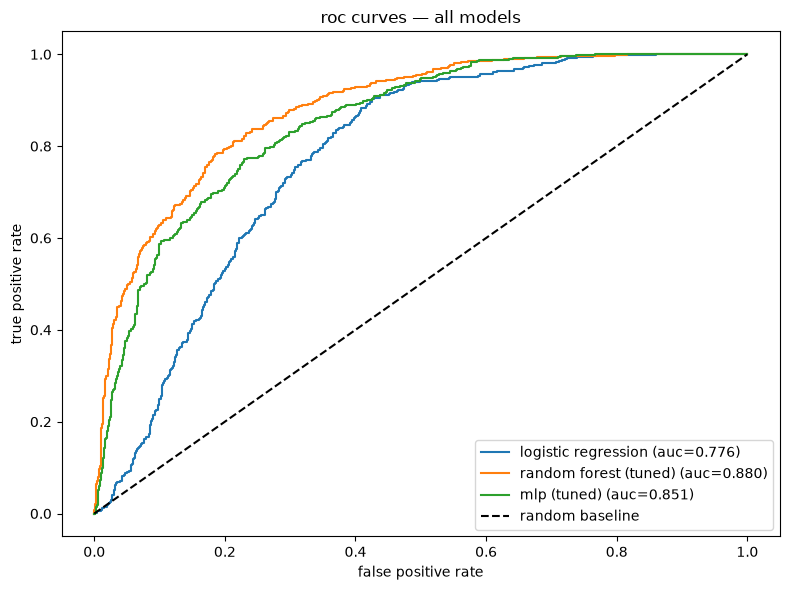

In [30]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (auc={auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='random baseline')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('roc curves — all models')
plt.legend()
plt.tight_layout()
plt.show()

#### Notes:

All three models perform well above the random baseline. Random forest sits highest followed by MLP then logistic regression. The curves are close together meaning all three models are learning the same underlying signal but with different capacity.

### F.4 Feature Importance (RF)

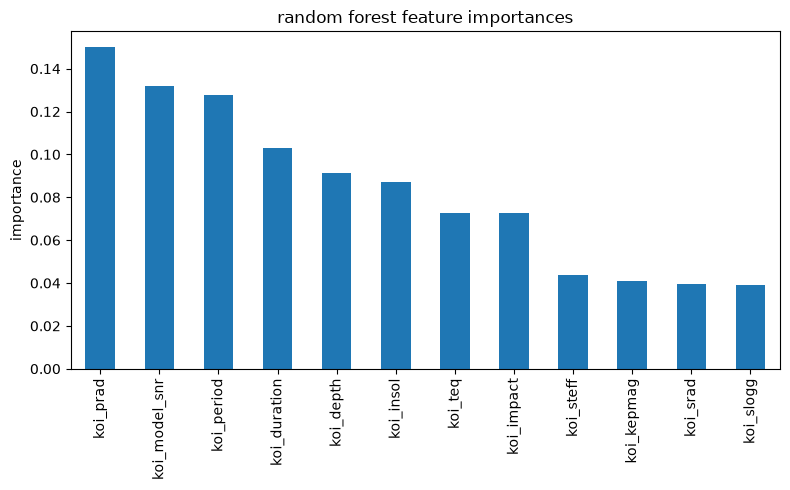

koi_prad         0.149923
koi_model_snr    0.131887
koi_period       0.127767
koi_duration     0.102813
koi_depth        0.091535
koi_insol        0.087220
koi_teq          0.072847
koi_impact       0.072457
koi_steff        0.043570
koi_kepmag       0.041152
koi_srad         0.039776
koi_slogg        0.039053
dtype: float64


In [31]:
#rf is the most interpretable of the nonlinear models
importances = rf_tuned_pipeline.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
feat_imp.plot(kind='bar')
plt.title('random forest feature importances')
plt.ylabel('importance')
plt.tight_layout()
plt.show()

print(feat_imp)

#### Notes:

The most important features are koi_prad, koi_model_snr, and koi_period, all measurements of the transit signal itself. This makes sense as a real planet real and consistent signal. Stellar properties like koi_slogg, koi_srad, and koi_kepmag are at the bottom more so the stars characteristics matter less than the quality of the signal it produces.

## F.5 Model Comparison

In [48]:
# summary comparison of all models on test set
results = {
    'model': ['logistic regression', 'random forest (tuned)', 'mlp (tuned)'],
    'accuracy': [0.6825, 0.8027, 0.7924],
    'f1': [0.6225, 0.6995, 0.6505],
    'roc_auc': [0.7762, 0.8795, 0.8506],
    'cv_roc_auc': [0.7608, 0.8614, 0.8355],
    'overfit_gap': [0.7649-0.7608, 0.9813-0.8614, 0.8959-0.8355]
}

results_df = pd.DataFrame(results).set_index('model')
print(results_df.round(4))

                       accuracy      f1  roc_auc  cv_roc_auc  overfit_gap
model                                                                    
logistic regression      0.6825  0.6225   0.7762      0.7608       0.0041
random forest (tuned)    0.8027  0.6995   0.8795      0.8614       0.1199
mlp (tuned)              0.7924  0.6505   0.8506      0.8355       0.0604


#### Notes:

Random forest has the best test performance but also the largest overfit gap at 0.1199, so it is the least stable of the three. MLP is in the middle with performance and overfit gap. Logistic regression is the most stable, it has basically no overfit gap, but also the weakest performance. More about this tradeoff later.

# G. Error Analysis

### G.1 Collect Misclassified Examples (using RF)

In [32]:
#use rf as main model for error analysis
y_pred_rf = rf_tuned_pipeline.predict(X_test)
y_prob_rf = rf_tuned_pipeline.predict_proba(X_test)[:, 1]

#rebuild test set with features for slicing
X_test_df = X_test.copy()
X_test_df['target'] = y_test.values
X_test_df['predicted'] = y_pred_rf
X_test_df['prob_candidate'] = y_prob_rf

#separate error types
false_negatives = X_test_df[(X_test_df['target'] == 1) & (X_test_df['predicted'] == 0)]  # missed planets
false_positives = X_test_df[(X_test_df['target'] == 0) & (X_test_df['predicted'] == 1)]  # false alarms

print(f"false negatives (missed candidates): {len(false_negatives)}")
print(f"false positives (wrongly flagged as candidate): {len(false_positives)}")

false negatives (missed candidates): 116
false positives (wrongly flagged as candidate): 171


#### Notes:

the tuned random forest got 116 false negatives and 171 false positives in the test set. so the model produces more false alarms than missed planets, meaning it is slightly biased toward predicting false positive.

### G.2 Failure Pattern Investigation

#### G.2.1 Summary Statistics of Error Types

In [53]:
#compare misclassified vs correctly classified on key features
correct = X_test_df[(X_test_df['target'] == X_test_df['predicted'])]

print("false negatives\n" , false_negatives[['koi_model_snr', 'koi_prad', 'koi_impact', 'koi_depth', 'koi_period']].describe().round(3))

print("false positives\n" , false_positives[['koi_model_snr', 'koi_prad', 'koi_impact', 'koi_depth', 'koi_period']].describe().round(3))

print("correct ones\n" , correct[['koi_model_snr', 'koi_prad', 'koi_impact', 'koi_depth', 'koi_period']].describe().round(3))

false negatives
        koi_model_snr  koi_prad  koi_impact   koi_depth  koi_period
count        116.000   116.000     116.000     116.000     116.000
mean          67.016    11.447       0.587    4099.134     133.852
std          185.973    20.816       0.405   16430.816     195.746
min            0.900     0.550       0.001      20.200       0.260
25%            9.175     1.482       0.254     176.225       2.038
50%           15.200     2.600       0.579     401.500      16.214
75%           31.025     9.702       0.891     833.975     255.864
max         1405.600   119.960       1.857  154280.000    1295.362
false positives
        koi_model_snr  koi_prad  koi_impact  koi_depth  koi_period
count        171.000   171.000     171.000    171.000     171.000
mean          19.236     3.435       0.415    611.746      85.577
std           36.398     5.661       0.340   1634.441     155.560
min            2.600     0.530       0.001     21.100       0.366
25%            8.950     1.205   

#### Notes:

for false negatives, the median SNR is 15.2, and the median planet radius is 2.6, these are small planets with weak signals. False positives have an even lower median SNR of 12.1 with small apparent radii, so these are ambiguous low signal objects that incorrectly get labeled as real candidates. Correctly classified examples have a mean SNR of 382, way more than both other groups, so the model is reliable when the signal is strong but doesnt do good in low-SNR regime.

#### G.2.2 SNR Distribution of Errors

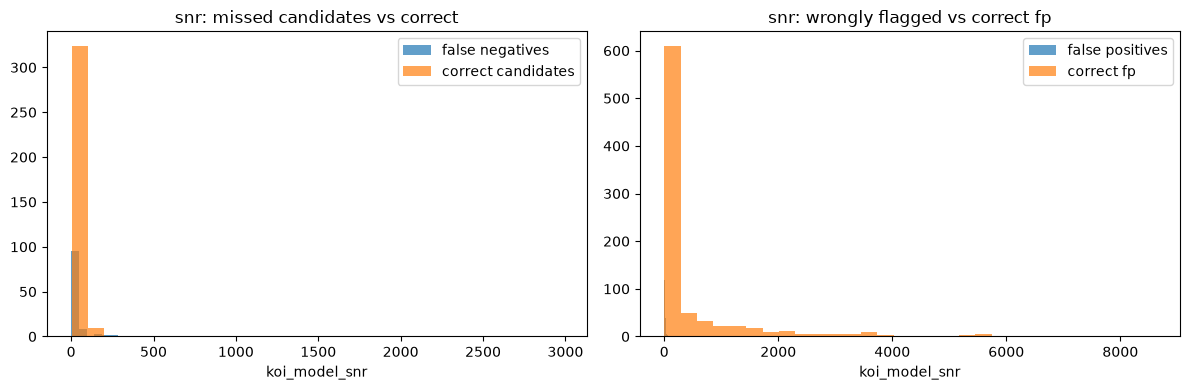

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(false_negatives['koi_model_snr'], bins=30, alpha=0.7, label='false negatives')
axes[0].hist(correct[correct['target']==1]['koi_model_snr'], bins=30, alpha=0.7, label='correct candidates')
axes[0].set_xlabel('koi_model_snr')
axes[0].set_title('snr: missed candidates vs correct')
axes[0].legend()

axes[1].hist(false_positives['koi_model_snr'], bins=30, alpha=0.7, label='false positives')
axes[1].hist(correct[correct['target']==0]['koi_model_snr'], bins=30, alpha=0.7, label='correct fp')
axes[1].set_xlabel('koi_model_snr')
axes[1].set_title('snr: wrongly flagged vs correct fp')
axes[1].legend()

plt.tight_layout()
plt.show()

#### Notes:

The left plot shows that missed candidates cluster at the same low SNR range as correctly classified candidates, just with weaker signals overall. The model gets most candidates right but struggles with faint signals.

The right plot has basically no false positives, so the model almost never confuses a false positive for a candidate when the signal is strong and clean. The errors are concentrated entirely in the low SNR region where candidates and false positives become hard to differentiate.

#### G.2.3 Impact Parameter of Errors

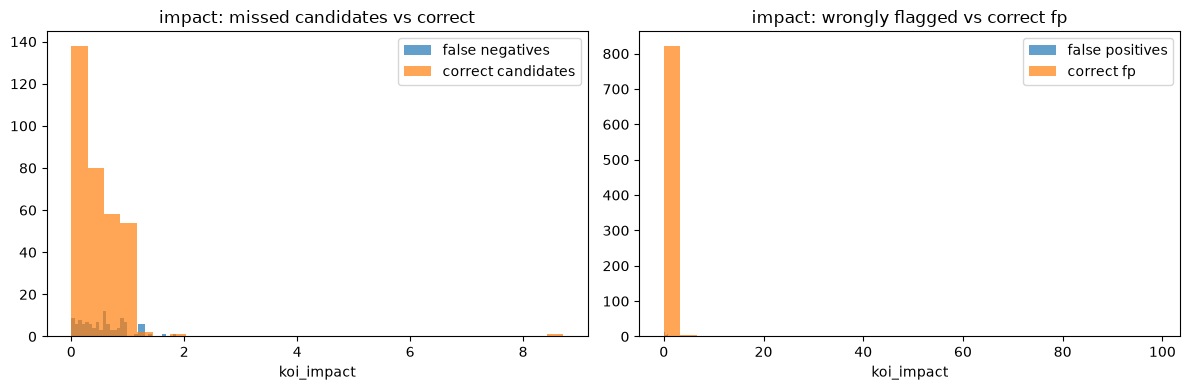

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(false_negatives['koi_impact'], bins=30, alpha=0.7, label='false negatives')
axes[0].hist(correct[correct['target']==1]['koi_impact'], bins=30, alpha=0.7, label='correct candidates')
axes[0].set_xlabel('koi_impact')
axes[0].set_title('impact: missed candidates vs correct')
axes[0].legend()

axes[1].hist(false_positives['koi_impact'], bins=30, alpha=0.7, label='false positives')
axes[1].hist(correct[correct['target']==0]['koi_impact'], bins=30, alpha=0.7, label='correct fp')
axes[1].set_xlabel('koi_impact')
axes[1].set_title('impact: wrongly flagged vs correct fp')
axes[1].legend()

plt.tight_layout()
plt.show()

### Notes:

Missed candidates are spread across the range of impact values and the model misses some candidates at all impact values, so weak signal strength is the primary driver of errors as opposed to transit geometry. The second plot shows basically 0 false positives across any impact value, same as what was seen in the SNR analysis. The models false alarms are not explained by impact parameter either, showing that low SNR ambiguity is the main failure mode.

#### G.2.4 Quantifying the SNR threshold effect

In [36]:
#check error rates by snr bucket
X_test_df['snr_bucket'] = pd.cut(X_test_df['koi_model_snr'],
                                   bins=[0, 10, 20, 50, 100, 10000],
                                   labels=['0-10', '10-20', '20-50', '50-100', '100+'])

snr_analysis = X_test_df.groupby('snr_bucket', observed=True).apply(
    lambda g: pd.Series({
        'total': len(g),
        'fn_rate': ((g['target']==1) & (g['predicted']==0)).sum() / max((g['target']==1).sum(), 1),
        'fp_rate': ((g['target']==0) & (g['predicted']==1)).sum() / max((g['target']==0).sum(), 1),
    })
).round(3)

print(snr_analysis)

            total  fn_rate  fp_rate
snr_bucket                         
0-10        299.0    0.234    0.364
10-20       496.0    0.232    0.281
20-50       209.0    0.250    0.163
50-100      102.0    0.348    0.038
100+        349.0    0.565    0.012


In [37]:
high_snr_fn = false_negatives[false_negatives['koi_model_snr'] > 100]

print(f"high-snr false negatives: {len(high_snr_fn)}")
print(high_snr_fn[['koi_model_snr', 'koi_prad', 'koi_impact',
                     'koi_depth', 'koi_period', 'prob_candidate']].describe().round(3))

high-snr false negatives: 13
       koi_model_snr  koi_prad  koi_impact   koi_depth  koi_period  \
count         13.000    13.000      13.000      13.000      13.000   
mean         441.923    24.125       0.703   25290.400     118.639   
std          395.904    18.994       0.415   41939.486     356.370   
min          124.600     7.310       0.001     372.200       0.604   
25%          185.300     8.250       0.580    3876.100       2.689   
50%          236.800    21.020       0.709    7343.400       3.262   
75%          527.800    29.910       0.938   37492.000      13.119   
max         1405.600    57.820       1.394  154280.000    1295.362   

       prob_candidate  
count          13.000  
mean            0.325  
std             0.119  
min             0.142  
25%             0.213  
50%             0.361  
75%             0.423  
max             0.485  


#### Notes:

The FP rate decreases from 0.364 in the 0-10 range down to 0.012 above 100 (clearly detectable transit signals), as SNR increases, so the model becomes very reliable at eliminating false positives when the signal is strong. However, the FN rate increases with SNR, reaching 0.565 above 100. This shows another failure mode separate from low SNR. High SNR candidates that get missed tend to be large planets with deep transits this is hard to distinguish from eclipsing binaries. The model has learned to be skeptical of this profile and underpredicts candidates of that type

#### G.2.5 Visualizing Failure Modes

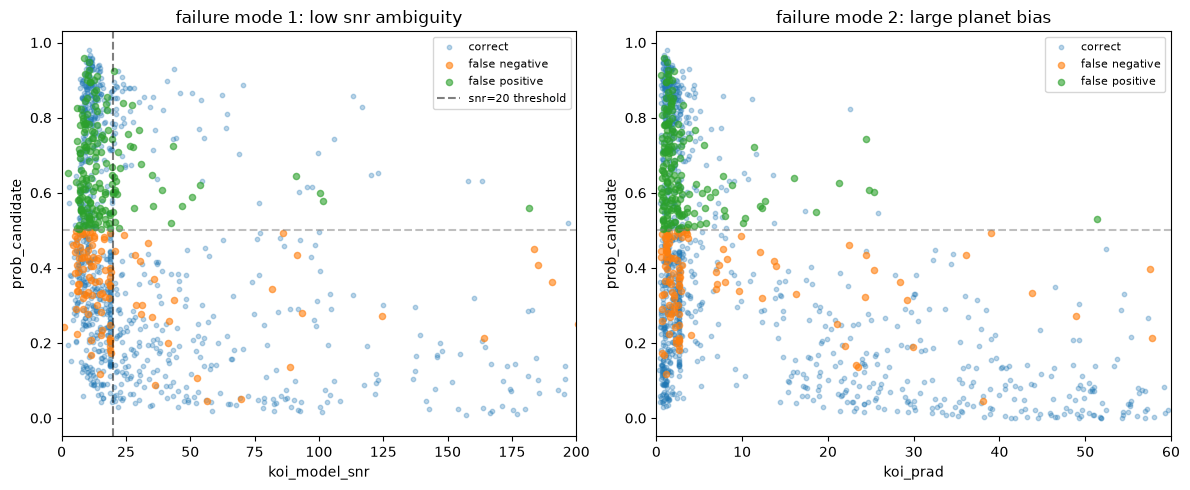

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# failure mode 1: low snr ambiguity
axes[0].scatter(X_test_df[X_test_df['predicted']==X_test_df['target']]['koi_model_snr'],
                X_test_df[X_test_df['predicted']==X_test_df['target']]['prob_candidate'],
                alpha=0.3, label='correct', s=10)
axes[0].scatter(false_negatives['koi_model_snr'], false_negatives['prob_candidate'],
                alpha=0.6, label='false negative', s=20)
axes[0].scatter(false_positives['koi_model_snr'], false_positives['prob_candidate'],
                alpha=0.6, label='false positive', s=20)
axes[0].axvline(x=20, color='black', linestyle='--', alpha=0.5, label='snr=20 threshold')
axes[0].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
axes[0].set_xlabel('koi_model_snr')
axes[0].set_ylabel('prob_candidate')
axes[0].set_xlim(0, 200)
axes[0].set_title('failure mode 1: low snr ambiguity')
axes[0].legend(fontsize=8)

# failure mode 2: high snr large planets
axes[1].scatter(X_test_df[X_test_df['predicted']==X_test_df['target']]['koi_prad'],
                X_test_df[X_test_df['predicted']==X_test_df['target']]['prob_candidate'],
                alpha=0.3, label='correct', s=10)
axes[1].scatter(false_negatives['koi_prad'], false_negatives['prob_candidate'],
                alpha=0.6, label='false negative', s=20)
axes[1].scatter(false_positives['koi_prad'], false_positives['prob_candidate'],
                alpha=0.6, label='false positive', s=20)
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('koi_prad')
axes[1].set_ylabel('prob_candidate')
axes[1].set_xlim(0, 60)
axes[1].set_title('failure mode 2: large planet bias')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

#### Notes:

This plot was added to visualize the two failure modes identified in G.2.4 side by side, putting the misclassified examples against the correctly classified ones.

The left plot shows the low SNR failure mode. Both false negatives and false positives group together below the SNR 20 threshold, with the 0.5 probability line separating FP above and FN below. The model is uncertain in this region, assigning probabilities close to 0.5 rather than confidently wrong.

The right plot shows the large planet bias. Most activity is concentrated below a radius of about 4, with false negatives below the 0.5 line even at larger radii.